# Formativa 2 — Primer modelo de compra y preparación para Sumativa 3

**Grupo 2:** Cristian Hurtado, Jorge Altamirano, Renzo Vilchez y Luis Paredes.  
**Asignatura:** MCDI501 — Estadística Computacional para la Toma de Decisiones.  
**Dataset:** Online Shoppers Purchasing Intention (UCI).

**Pregunta:** ¿qué capacidad tiene un modelo logístico sencillo, informado por S1 y S2,
para discriminar sesiones con y sin compra, y qué limitaciones aparecen al preparar los datos?

Este notebook desarrolla el flujo de la **Formativa 2**, según el correo docente de apoyo:
faltantes MCAR artificiales, imputación simple, partición 70/30 estratificada, 3–5 variables,
regresión logística, odds ratios, VIF y evaluación. Es la base de S3, no su entrega completa.
Los tres modelos, la imputación por regresión, ponderación de clases y bootstrap de
coeficientes se incorporarán en S3. No se presupone que el modelo inicial alcance un recall alto.

**Recorrido:** 0 entorno → 1 evidencia previa → 2 faltantes y partición → 3 preparación
→ 4 modelo e interpretación → 5 evaluación → 6 imputación y límites → 7 cierre y revisión.

**Momento de uso:** se estudian resúmenes agregados de sesión. Sin tiempos de eventos no
afirmamos que todas estas mediciones estén disponibles antes de comprar ni que el modelo
sea una herramienta de predicción en tiempo real. PageValues se excluye por disponibilidad
temporal no confirmada. Los resultados son predictivos/observacionales, no causales.

## 0. Comprobación del kernel y configuración

Usar la **misma `.venv` de este repositorio** que en S2. La primera celda comprueba Python,
versiones e importaciones antes del análisis; no instala paquetes ni modifica el entorno.
Ejecutar con **Restart Kernel → Run All**, esperar el final y guardar.
Todo el código utiliza las dependencias existentes: no se requiere statsmodels para esta formativa.

In [14]:
# Comprobación del kernel antes de importar las librerías del análisis.
# Esta celda solo revisa: no instala paquetes ni cambia configuraciones.
from pathlib import Path as _KernelPath
from importlib import metadata as _kernel_metadata
from importlib import import_module as _kernel_importar
import sys as _kernel_sys
import os as _kernel_os

def comprobar_kernel_proyecto():
    inicio = _KernelPath.cwd().resolve()
    raiz = next((p for p in (inicio, *inicio.parents)
                 if (p/'requirements.txt').is_file() and (p/'data/raw').is_dir()), None)
    errores, avisos, paquetes = [], [], []
    python_referencia = (3, 13, 5)
    python_actual = tuple(_kernel_sys.version_info[:3])
    print('COMPROBACIÓN DEL KERNEL — GRUPO 2')
    print('Python actual:', '.'.join(map(str, python_actual)))
    print('Python usado para validar el proyecto: 3.13.5')
    print('Intérprete:', _kernel_sys.executable)
    if raiz is None:
        errores.append('No se encuentra la raíz del proyecto. Abra la carpeta proyectoGrupo2 en VS Code.')
    if python_actual[:2] != python_referencia[:2]:
        errores.append('La versión mayor/menor de Python no coincide con la referencia 3.13.')
    elif python_actual != python_referencia:
        avisos.append('La revisión de Python difiere de 3.13.5; se comprueban también versiones e importaciones.')
    if raiz is not None:
        esperado = raiz/'.venv'/('Scripts/python.exe' if _kernel_os.name == 'nt' else 'bin/python')
        print('Entorno local esperado:', esperado)
        if _kernel_os.path.normcase(str(_KernelPath(_kernel_sys.executable).resolve())) != _kernel_os.path.normcase(str(esperado.resolve())):
            avisos.append('Está usando otro intérprete. Si las versiones e importaciones pasan, puede ser compatible; '
                          'para reproducir el entorno del grupo seleccione la .venv de este proyecto.')
        modulos = {'scikit-learn': 'sklearn'}
        for linea in (raiz/'requirements.txt').read_text(encoding='utf-8').splitlines():
            linea = linea.split('#', 1)[0].strip()
            if '==' not in linea:
                continue
            nombre, requerida = (v.strip() for v in linea.split('==', 1))
            try:
                instalada = _kernel_metadata.version(nombre)
            except _kernel_metadata.PackageNotFoundError:
                instalada = 'NO INSTALADA'
            estado = 'OK' if instalada == requerida else 'REVISAR'
            importacion = 'no comprobada'
            if instalada == requerida:
                try:
                    _kernel_importar(modulos.get(nombre, nombre.replace('-', '_')))
                    importacion = 'OK'
                except Exception as exc:
                    estado = 'ERROR AL IMPORTAR'
                    importacion = f'{type(exc).__name__}: {exc}'
                    errores.append(f'{nombre}: no pudo importarse ({importacion}).')
            else:
                errores.append(f'{nombre}: {instalada}; se requiere {requerida}.')
            paquetes.append({'paquete': nombre, 'instalada': instalada, 'requerida': requerida,
                             'estado': estado, 'importacion': importacion})
        print()
        print(f'{"Librería":<16} {"Instalada":<17} {"Requerida":<13} Estado')
        print('-'*70)
        for fila in paquetes:
            print(f'{fila["paquete"]:<16} {fila["instalada"]:<17} {fila["requerida"]:<13} {fila["estado"]}')
    for aviso in avisos:
        print('AVISO:', aviso)
    if errores:
        print()
        print('ENTORNO CON PROBLEMAS — revise el kernel antes de continuar.')
        for error in errores:
            print(' -', error)
        print('En VS Code: Select Kernel > Select Another Kernel > Python Environments > .venv de Curso 02.')
        print('Después reinicie el kernel y ejecute Run All. Esta celda no instala ni modifica nada.')
    elif avisos:
        print()
        print('LIBRERÍAS CORRECTAS — versiones e importaciones verificadas; revise los avisos del intérprete.')
    else:
        print()
        print('ENTORNO CORRECTO — Python, intérprete y todas las librerías están verificados.')
        print('Puede continuar con el notebook.')
    return {'correcto': not errores, 'errores': errores, 'avisos': avisos,
            'python': '.'.join(map(str, python_actual)), 'interprete': _kernel_sys.executable,
            'paquetes': paquetes}

diagnostico_kernel = comprobar_kernel_proyecto()
if not diagnostico_kernel['correcto']:
    raise RuntimeError('El entorno no coincide con el proyecto. Revise los detalles y pasos indicados arriba.')

COMPROBACIÓN DEL KERNEL — GRUPO 2
Python actual: 3.13.5
Python usado para validar el proyecto: 3.13.5
Intérprete: d:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2\.venv\Scripts\python.exe
Entorno local esperado: D:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2\.venv\Scripts\python.exe

Librería         Instalada         Requerida     Estado
----------------------------------------------------------------------
ipykernel        7.3.0             7.3.0         OK
jupyterlab       4.6.3             4.6.3         OK
matplotlib       3.11.2            3.11.2        OK
notebook         7.6.2             7.6.2         OK
numpy            2.5.3             2.5.3         OK
pandas           3.0.5             3.0.5         OK
scikit-learn     1.9.1             1.9.1         OK
scipy            1.18.1            1.18.1        OK

ENTORNO CORRECTO — Python, intérprete y todas las librerías están verificados.
Puede continuar con el notebook.


In [15]:
from pathlib import Path
from importlib import metadata
from time import perf_counter
import hashlib, json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay, mean_absolute_error, mean_squared_error, make_scorer)
from sklearn.exceptions import ConvergenceWarning

RAIZ=next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
          if (p/'requirements.txt').is_file() and (p/'data/raw').is_dir())
SEED_MCAR=42
SEED_SPLIT=42
SEED_CV=20261022
FRACCION_MCAR=.10
VARIABLE_MCAR='ProductRelated_Duration'
UMBRAL=.50
CV_FOLDS=5
NUEVOS_ARCHIVOS=['Formativa2/Modelamiento_Predictivo.ipynb',
                 'data/preparacion_modelamiento.json','Formativa2/resultados_formativa2.json']
COLOR=['#2f6173','#b41928','#b57617','#64748b']
FIGURAS=TABLAS=0
INICIO=perf_counter()
def numero(x,dec=3):
    return f'{x:,.{dec}f}'.replace(',','X').replace('.',',').replace('X','.')
def tabla(df,titulo):
    global TABLAS
    TABLAS+=1
    display(Markdown(f'**Tabla {TABLAS}. {titulo}**'))
    formatos={c:(lambda x: numero(x,4)) for c in df.select_dtypes(include='floating').columns}
    display(df.style.format(formatos))
def figura(titulo):
    global FIGURAS
    FIGURAS+=1
    plt.show()
    display(Markdown(f'**Figura {FIGURAS}. {titulo}** Fuente: elaboración del grupo, datos UCI.'))
def sha_lf(path):
    return hashlib.sha256(path.read_bytes().replace(b'\r\n',b'\n')).hexdigest()
def registros(df):
    return df.astype(object).where(pd.notna(df),None).to_dict(orient='records')
VERSIONES={p:metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib']}
plt.rcParams.update({'figure.dpi':115,'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':.15,'font.size':10})
print('Raíz:',RAIZ)
print('Semillas: MCAR',SEED_MCAR,'| partición',SEED_SPLIT,'| validación',SEED_CV)

Raíz: D:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2
Semillas: MCAR 42 | partición 42 | validación 20261022


## 1. Punto de partida: decisiones informadas por S1 y S2

Se leen los resultados ya obtenidos, sin repetir EDA ni inferencia. Se verifica el contenido
del CSV con el hash normalizado de S1 y se comprueba que no existen faltantes naturales.

| Evidencia previa | Decisión en esta formativa |
|---|---|
| S1: 12.330 sesiones, 1.908 compras, cero faltantes | Declarar los faltantes nuevos como artificiales MCAR, no reinterpretar S1. |
| S2: páginas/duración ρ≈0,883 y rebote/salida ρ≈0,602, con IC que excluyen cero | Revisar redundancia mediante VIF de la matriz realmente usada; no confundir Spearman con VIF. |
| S2: magnitudes sensibles a las colas | Conservar registros, usar log1p para páginas/duración y documentar transformación; no borrar extremos sin evidencia de error. |
| S1/S2: compras minoritarias | Estratificación y comparación con predecir siempre no compra; no evaluar solo accuracy. |
| Retroalimentación: PageValues sin disponibilidad previa confirmada | Excluirla del conjunto de predictores. |
| S1: conversiones diferentes según VisitorType; S2: escenarios por composición | Incluir tipo de visitante como candidata categórica, sin tratar la simulación como validación de causalidad. |

Las asociaciones entre predictores no demuestran utilidad predictiva para Revenue. Solo
fundamentan candidatos y diagnósticos; el desempeño se evalúa después. S1/S2 exploraron
el dataset completo: este holdout no equivale a validación externa ni borra esa exploración previa.

In [16]:
CSV=RAIZ/'data/raw/online_shoppers_intention.csv'
S1_PATH=RAIZ/'S1/resultados_s1.json'
S2_PATH=RAIZ/'S2/resultados_validados.json'
S1=json.loads(S1_PATH.read_text(encoding='utf-8'))
S2=json.loads(S2_PATH.read_text(encoding='utf-8'))
HASH_CSV=sha_lf(CSV)
assert HASH_CSV==S1['procedencia']['sha256_csv_LF'], 'El CSV cambió respecto de S1.'
assert len(S2['bootstrap_diferencias_medias'])==2 and len(S2['bootstrap_medianas'])==3,     'La referencia de S2 no incluye las últimas ampliaciones; revisar la versión del equipo.'
original=pd.read_csv(CSV)
assert original.Revenue.dtype==bool and original.Weekend.dtype==bool
assert len(original)==S1['n'] and int(original.Revenue.sum())==S1['compras']
assert original.isna().sum().sum()==0, 'El archivo ya contiene faltantes; no aplicar automáticamente el experimento MCAR.'
assert original.index.equals(pd.RangeIndex(len(original)))
tabla_s1=pd.DataFrame([
    {'hallazgo':'Sesiones','valor':str(S1['n'])},
    {'hallazgo':'Compras','valor':str(S1['compras'])},
    {'hallazgo':'Conversión','valor':numero(100*S1['p_compra'],2)+' %'},
    {'hallazgo':'Faltantes naturales','valor':'0'},
    {'hallazgo':'Filas idénticas adicionales','valor':str(S1['filas_identicas_adicionales'])}])
tabla(tabla_s1,'Referencia de S1 verificada con el CSV original')
correlaciones_s2=pd.DataFrame(S2['correlaciones'])
tabla(correlaciones_s2[['relacion','rho_S1','IC95_inf','IC95_sup']],
      'Correlaciones ya validadas en S2: evidencia para revisar redundancia')

**Tabla 1. Referencia de S1 verificada con el CSV original**

,hallazgo,valor
0,Sesiones,12330
1,Compras,1908
2,Conversión,"15,47 %"
3,Faltantes naturales,0
4,Filas idénticas adicionales,125


**Tabla 2. Correlaciones ya validadas en S2: evidencia para revisar redundancia**

,relacion,rho_S1,IC95_inf,IC95_sup
0,Páginas de productos / Duración en productos (min),"0,8827","0,8774","0,8877"
1,Rebote (%) / Salida (%),"0,6023","0,5884","0,6159"
2,Páginas de productos / Salida (%),"-0,5189","-0,5331","-0,5047"


## 2. Faltantes MCAR del 10 % y partición común para Formativa 2 y S3

Se seleccionan **exactamente 1.233 posiciones** de ProductRelated_Duration, sin reemplazo,
con igual probabilidad e independencia de los valores y Revenue. El 10 % es el límite
inferior del rango 10–15 % solicitado; no es un porcentaje estadísticamente óptimo.
El mecanismo MCAR se conoce porque lo construimos; no se infiere de una prueba de asociación.

**Persistencia:** `data/preparacion_modelamiento.json` registra hash del CSV, posiciones,
valores verdaderos y filas de entrenamiento/prueba. Si existe, se reutiliza y valida;
no se sobreescribe ni se genera otra máscara. El CSV original no se modifica. Así se
reconstruye la misma versión con faltantes sin mantener un segundo CSV completo.

Los valores verdaderos guardados están reservados para evaluar el error de imputación:
no se pasan a los imputadores, transformadores ni clasificador. La partición 70/30 se
estratifica por Revenue con semilla fija. No se divide de nuevo en cada comparación.

In [17]:
PROTOCOLO_PATH=RAIZ/'data/preparacion_modelamiento.json'
CONFIG_PREPARACION={'variable':VARIABLE_MCAR,'fraccion':FRACCION_MCAR,
    'semilla_MCAR':SEED_MCAR,'semilla_split':SEED_SPLIT,'test_size':.30,
    'estratificacion':'Revenue','seleccion':'muestreo uniforme sin reemplazo; tamaño fijo'}
if not PROTOCOLO_PATH.exists():
    n_ocultar=int(round(len(original)*FRACCION_MCAR))
    ocultas=np.sort(np.random.default_rng(SEED_MCAR).choice(len(original),size=n_ocultar,replace=False))
    filas_train,filas_test=train_test_split(np.arange(len(original)),test_size=.30,
        stratify=original.Revenue.to_numpy(),random_state=SEED_SPLIT)
    protocolo={'schema_version':1,'csv':'data/raw/online_shoppers_intention.csv',
        'sha256_csv_LF':HASH_CSV,'configuracion':CONFIG_PREPARACION,
        'posiciones_ocultas':ocultas.tolist(),
        'valores_originales_ocultos':original.loc[ocultas,VARIABLE_MCAR].tolist(),
        'filas_train':sorted(map(int,filas_train)), 'filas_test':sorted(map(int,filas_test)),
        'uso_valores_originales':'Solo auditoría y error de imputación; nunca predictores ni ajuste.'}
    # Modo exclusivo: impedir sobrescribir una preparación ya guardada.
    with PROTOCOLO_PATH.open('x',encoding='utf-8') as f:
        json.dump(protocolo,f,ensure_ascii=False,indent=2,allow_nan=False)
    print('Preparación creada una vez y guardada para Formativa 2 / S3.')
else:
    print('Preparación existente reutilizada: no se cambian faltantes ni partición.')
protocolo=json.loads(PROTOCOLO_PATH.read_text(encoding='utf-8'))
assert protocolo['sha256_csv_LF']==HASH_CSV
assert protocolo['configuracion']==CONFIG_PREPARACION, 'Configuración distinta: revisar; no sobrescribir la preparación.'
ocultas=np.array(protocolo['posiciones_ocultas'],dtype=int)
train_idx=np.array(protocolo['filas_train'],dtype=int)
test_idx=np.array(protocolo['filas_test'],dtype=int)
assert len(ocultas)==1233 and len(np.unique(ocultas))==1233
assert np.allclose(original.loc[ocultas,VARIABLE_MCAR],protocolo['valores_originales_ocultos'],rtol=0,atol=0)
assert len(train_idx)==8631 and len(test_idx)==3699
assert not set(train_idx)&set(test_idx)
assert set(train_idx)|set(test_idx)==set(original.index)
datos=original.copy(deep=True)
datos.loc[ocultas,VARIABLE_MCAR]=np.nan
assert datos[VARIABLE_MCAR].isna().sum()==1233 and datos.isna().sum().sum()==1233
pd.testing.assert_series_equal(datos.Revenue,original.Revenue)
# A partir de aquí las tablas de modelamiento usan solo la versión con faltantes.
X=datos.drop(columns='Revenue'); y=datos.Revenue.astype(int)
X_train=X.loc[train_idx].copy();X_test=X.loc[test_idx].copy()
y_train=y.loc[train_idx].copy();y_test=y.loc[test_idx].copy()
tabla_particion=pd.DataFrame([
    {'conjunto':nombre,'n':len(idx),'compras':int(y.loc[idx].sum()),
     'compras_%':100*y.loc[idx].mean(),'faltantes_duracion':int(datos.loc[idx,VARIABLE_MCAR].isna().sum())}
    for nombre,idx in [('Entrenamiento',train_idx),('Prueba',test_idx)]])
tabla(tabla_particion,'Partición fija 70/30 estratificada y faltantes por conjunto')
tabla(pd.DataFrame([{'variable':VARIABLE_MCAR,'n_total':len(datos),'faltantes':1233,
    'faltantes_%':100*1233/len(datos),'mecanismo':'MCAR artificial','unidad_original':'segundos'}]),
    'Única variable con faltantes generados para el ejercicio')

Preparación existente reutilizada: no se cambian faltantes ni partición.


**Tabla 3. Partición fija 70/30 estratificada y faltantes por conjunto**

,conjunto,n,compras,compras_%,faltantes_duracion
0,Entrenamiento,8631,1336,"15,4791",854
1,Prueba,3699,572,"15,4636",379


**Tabla 4. Única variable con faltantes generados para el ejercicio**

,variable,n_total,faltantes,faltantes_%,mecanismo,unidad_original
0,ProductRelated_Duration,12330,1233,"10,0000",MCAR artificial,segundos


## 3. Preparación informada por S1/S2 y revisión de multicolinealidad

Se consideran cinco variables originales: **ProductRelated, ProductRelated_Duration,
BounceRates, ExitRates y VisitorType**. Para el primer modelo parsimonioso se priorizan
**duración, salida y tipo de visitante**, con tres variables originales (VisitorType genera
dos indicadores). Esta elección, fijada sin consultar el desempeño en prueba, evita acumular
los dos miembros de cada par redundante: duración representa tiempo y es la variable del
ejercicio MCAR; salida representa el abandono observado en S1. No se afirma que los otros
predictores carezcan de información: su comparación formal se reserva a S3.

Se calcula VIF de candidatos y del diseño final **solo en entrenamiento**, tras preparación.
VIF se obtiene de regresiones auxiliares con intercepto: 1/(1−R²). Valores por encima de 5
son una alerta orientativa, no una regla universal. Spearman alto no implica un VIF concreto.

**Transformaciones:** mediana aprendida en entrenamiento; duración pasa de segundos a minutos
y luego log1p; páginas utiliza log1p; tasas pasan a porcentaje. Las numéricas se estandarizan
con media y desviación de entrenamiento. No se eliminan ni recortan extremos ni filas idénticas:
S2 mostró sensibilidad de magnitud, pero no confirmó errores. VisitorType se codifica con
recurrentes como referencia, usando las categorías documentadas en S1.

Imputación por mediana ocurre antes del logaritmo. Todo se encapsula en pipelines para que
cada fold de validación aprenda su propia mediana y escala. PageValues y Revenue nunca son
predictores ni variables de imputación.

In [18]:
CANDIDATAS_NUM=['ProductRelated','ProductRelated_Duration','BounceRates','ExitRates']
NUMERICAS=['ProductRelated_Duration','ExitRates']
CATEGORICAS=['VisitorType']
PREDICTORES=NUMERICAS+CATEGORICAS
CATEGORIAS_VISITA=['Returning_Visitor','New_Visitor','Other']
def log_paginas(a):return np.log1p(a)
def log_duracion_min(a):return np.log1p(a/60.)
def porcentaje(a):return a*100.
def preparar_columnas(numericas):
    bloques=[]
    for c in numericas:
        funcion=(log_duracion_min if c=='ProductRelated_Duration' else
                 log_paginas if c=='ProductRelated' else porcentaje)
        bloques.append((c,Pipeline([
            ('imputacion',SimpleImputer(strategy='median')),
            ('unidad_y_transformacion',FunctionTransformer(funcion,feature_names_out='one-to-one')),
            ('escala',StandardScaler())]),[c]))
    bloques.append(('VisitorType',OneHotEncoder(categories=[CATEGORIAS_VISITA],drop='first',
        handle_unknown='error',sparse_output=False),CATEGORICAS))
    return ColumnTransformer(bloques,remainder='drop',verbose_feature_names_out=False)

def calcular_vif(matriz,nombres,escenario):
    m=np.asarray(matriz,dtype=float)
    assert np.isfinite(m).all() and (m.std(axis=0)>0).all()
    filas=[]
    for j,nombre in enumerate(nombres):
        otras=np.delete(m,j,axis=1)
        r2=LinearRegression().fit(otras,m[:,j]).score(otras,m[:,j])
        filas.append({'escenario':escenario,'predictor':nombre,'R2_auxiliar':r2,
                      'VIF':1/max(1-r2,np.finfo(float).eps)})
    return pd.DataFrame(filas)

prep_candidatas=preparar_columnas(CANDIDATAS_NUM)
matriz_candidatas=prep_candidatas.fit_transform(X_train)
vif_candidatas=calcular_vif(matriz_candidatas,prep_candidatas.get_feature_names_out(),'Cinco variables candidatas')
prep_diagnostico=preparar_columnas(NUMERICAS)
matriz_final=prep_diagnostico.fit_transform(X_train)
vif_final=calcular_vif(matriz_final,prep_diagnostico.get_feature_names_out(),'Tres variables del modelo inicial')
tabla(vif_candidatas,'VIF del diseño candidato, incluidas las dos dummies de VisitorType')
tabla(vif_final,'VIF de la especificación inicial elegida, sin utilizar prueba')
display(Markdown('**Lectura:** el VIF máximo pasa de **'+numero(vif_candidatas.VIF.max(),2)+
    '** a **'+numero(vif_final.VIF.max(),2)+'**. Es un diagnóstico de redundancia del diseño; '+
    'no garantiza que el modelo sea correcto ni que las variables descartadas sean inútiles.'))

**Tabla 5. VIF del diseño candidato, incluidas las dos dummies de VisitorType**

,escenario,predictor,R2_auxiliar,VIF
0,Cinco variables candidatas,ProductRelated,"0,7659","4,2723"
1,Cinco variables candidatas,ProductRelated_Duration,"0,7279","3,6753"
2,Cinco variables candidatas,BounceRates,"0,8454","6,4677"
3,Cinco variables candidatas,ExitRates,"0,8832","8,5642"
4,Cinco variables candidatas,VisitorType_New_Visitor,"0,1351","1,1562"
5,Cinco variables candidatas,VisitorType_Other,"0,0113","1,0115"


**Tabla 6. VIF de la especificación inicial elegida, sin utilizar prueba**

,escenario,predictor,R2_auxiliar,VIF
0,Tres variables del modelo inicial,ProductRelated_Duration,"0,3730","1,5948"
1,Tres variables del modelo inicial,ExitRates,"0,3863","1,6296"
2,Tres variables del modelo inicial,VisitorType_New_Visitor,"0,0934","1,1030"
3,Tres variables del modelo inicial,VisitorType_Other,"0,0070","1,0070"


**Lectura:** el VIF máximo pasa de **8,56** a **1,63**. Es un diagnóstico de redundancia del diseño; no garantiza que el modelo sea correcto ni que las variables descartadas sean inútiles.

## 4. Un modelo de regresión logística e interpretación de odds ratios

Se modela la probabilidad de Revenue=1 mediante un logit lineal en las variables transformadas.
El ajuste utiliza máxima verosimilitud **sin penalización** (`C=np.inf`), intercepto y solver
LBFGS. No se buscan hiperparámetros ni se selecciona el umbral con prueba.

Esta es la referencia **sin ponderación de clase** de Formativa 2, conforme al correo docente.
La ponderación será una ampliación explícita de S3, comparada con esta base. Se calcula ya
el peso que correspondería con la fórmula balanceada N/(2·n_clase), usando solo entrenamiento.

Un odds ratio es exp(coeficiente): describe un cambio multiplicativo en odds, manteniendo
los demás predictores constantes; no es un cambio porcentual directo en probabilidad.
Para duración el incremento es una desviación estándar de **log1p(minutos)**, no un minuto.
Para salida es una desviación estándar de la tasa; para categorías se compara con recurrentes.
En esta formativa los OR son puntuales: no se concluye significación sin intervalos; los IC
tradicionales y bootstrap del modelo elegido corresponden a S3.

In [19]:
modelo=Pipeline([
    ('preparacion',preparar_columnas(NUMERICAS)),
    ('logistica',LogisticRegression(C=np.inf,solver='lbfgs',max_iter=3000,
        tol=1e-9,class_weight=None,random_state=SEED_SPLIT))])
with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning)
    modelo.fit(X_train[PREDICTORES],y_train)
assert 'PageValues' not in PREDICTORES and 'Revenue' not in PREDICTORES
assert np.isfinite(modelo.named_steps['logistica'].coef_).all()
n_iter=int(modelo.named_steps['logistica'].n_iter_[0])
assert n_iter<3000, 'Se alcanzó el límite de iteraciones: revisar convergencia.'
print('Entrenamiento completado. Iteraciones:',n_iter,'| penalización: ninguna | ponderación: ninguna')
prep=modelo.named_steps['preparacion']
features=prep.get_feature_names_out().tolist()
beta=modelo.named_steps['logistica'].coef_[0]
filas_coef=[]
for nombre,b in zip(features,beta):
    if nombre in NUMERICAS:
        scaler=prep.named_transformers_[nombre].named_steps['escala']
        unidad=('1 DE de log1p(duración en minutos)' if nombre==VARIABLE_MCAR else '1 DE de salida en puntos porcentuales')
        valor_de=float(scaler.scale_[0])
        lectura=('Mayores odds' if b>0 else 'Menores odds')+' por el incremento indicado, condicionando en los demás predictores.'
    else:
        unidad=nombre.replace('VisitorType_','')+' frente a Returning_Visitor'
        valor_de=None
        lectura=('Mayores odds' if b>0 else 'Menores odds')+' frente a recurrentes, condicionando en las numéricas.'
    filas_coef.append({'predictor':nombre,'coeficiente':float(b),'odds_ratio':float(np.exp(b)),
                      'contraste':unidad,'DE_entrenamiento_transformada':valor_de,'lectura':lectura})
tabla_coef=pd.DataFrame(filas_coef)
tabla(tabla_coef.drop(columns='DE_entrenamiento_transformada'),'Coeficientes y odds ratios puntuales del único modelo')
intercepto=float(modelo.named_steps['logistica'].intercept_[0])
display(Markdown('Intercepto: **'+numero(intercepto)+'**. Corresponde a numéricas en su media transformada de entrenamiento y visitante recurrente.'))
conteos=y_train.value_counts().sort_index()
pesos_s3=pd.DataFrame([{'clase':int(c),'n_train':int(n),'peso_balanceado_para_S3':len(y_train)/(2*n)}
                       for c,n in conteos.items()])
tabla(pesos_s3,'Pesos de clase que se evaluarán en S3; aún no aplicados al modelo inicial')

Entrenamiento completado. Iteraciones: 22 | penalización: ninguna | ponderación: ninguna


**Tabla 7. Coeficientes y odds ratios puntuales del único modelo**

,predictor,coeficiente,odds_ratio,contraste,lectura
0,ProductRelated_Duration,"0,4619","1,5870",1 DE de log1p(duración en minutos),"Mayores odds por el incremento indicado, condicionando en los demás predictores."
1,ExitRates,"-1,4351","0,2381",1 DE de salida en puntos porcentuales,"Menores odds por el incremento indicado, condicionando en los demás predictores."
2,VisitorType_New_Visitor,"0,5029","1,6536",New_Visitor frente a Returning_Visitor,"Mayores odds frente a recurrentes, condicionando en las numéricas."
3,VisitorType_Other,"0,5664","1,7620",Other frente a Returning_Visitor,"Mayores odds frente a recurrentes, condicionando en las numéricas."


Intercepto: **-2,377**. Corresponde a numéricas en su media transformada de entrenamiento y visitante recurrente.

**Tabla 8. Pesos de clase que se evaluarán en S3; aún no aplicados al modelo inicial**

,clase,n_train,peso_balanceado_para_S3
0,0,7295,"0,5916"
1,1,1336,"3,2302"


### 4.1 Validación interna antes de evaluar prueba

Se usa validación cruzada estratificada de cinco folds, únicamente en entrenamiento.
El pipeline se reajusta completo en cada fold; ninguna mediana o escala del fold de validación
se aprende con ese fold. La especificación y el umbral 0,5 están fijados de antemano.
Estos cinco ajustes son réplicas de validación del mismo modelo, no cinco modelos candidatos.
La desviación entre folds es descriptiva, no un intervalo de confianza.
La elección informada por S1/S2 y el diagnóstico de VIF preceden a esta validación;
no es validación anidada de todo el proceso exploratorio.
Si un fold no predice compras, precision se informa como 0 por convención (`zero_division=0`); esto es una limitación del punto de operación, no un fallo de ejecución.

In [20]:
cv=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED_CV)
scoring={'ROC_AUC':'roc_auc','PR_AP':'average_precision','accuracy':'accuracy',
         'precision':make_scorer(precision_score,zero_division=0),'recall':'recall','F1':'f1'}
with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning)
    validacion=cross_validate(modelo,X_train[PREDICTORES],y_train,cv=cv,scoring=scoring,
        n_jobs=1,return_train_score=False,error_score='raise',return_estimator=True)
tabla_cv=pd.DataFrame({nombre:validacion['test_'+nombre] for nombre in scoring})
tabla_cv.insert(0,'fold',np.arange(1,CV_FOLDS+1))
resumen_cv=pd.DataFrame([{'metrica':c,'media':tabla_cv[c].mean(),'DE_entre_folds':tabla_cv[c].std(ddof=1)}
                        for c in scoring])
tabla(tabla_cv,'Validación interna en entrenamiento, con preparación aprendida por fold')
tabla(resumen_cv,'Resumen de validación cruzada: medias y dispersión entre folds')
medianas_cv=[float(est.named_steps['preparacion'].named_transformers_[VARIABLE_MCAR]
                   .named_steps['imputacion'].statistics_[0]) for est in validacion['estimator']]
assert len(medianas_cv)==5 and np.isfinite(medianas_cv).all()
print('Medianas de duración aprendidas por los cinco folds (segundos):',medianas_cv)

**Tabla 9. Validación interna en entrenamiento, con preparación aprendida por fold**

,fold,ROC_AUC,PR_AP,accuracy,precision,recall,F1
0,1,"0,7549","0,3420","0,8448","0,0000","0,0000","0,0000"
1,2,"0,7442","0,3164","0,8447","0,3333","0,0037","0,0074"
2,3,"0,7271","0,2829","0,8453","0,5000","0,0075","0,0148"
3,4,"0,7425","0,3222","0,8453","0,0000","0,0000","0,0000"
4,5,"0,7186","0,2770","0,8436","0,0000","0,0000","0,0000"


**Tabla 10. Resumen de validación cruzada: medias y dispersión entre folds**

,metrica,media,DE_entre_folds
0,ROC_AUC,"0,7375","0,0144"
1,PR_AP,"0,3081","0,0275"
2,accuracy,"0,8447","0,0007"
3,precision,"0,1667","0,2357"
4,recall,"0,0022","0,0033"
5,F1,"0,0044","0,0066"


Medianas de duración aprendidas por los cinco folds (segundos): [589.875, 598.55, 597.25, 600.44833335, 588.0416667]


## 5. Evaluación en entrenamiento y prueba, sin cambiar el umbral

Se evalúa el pipeline ya ajustado con umbral **0,5**, sin ponderación ni ajuste del umbral.
La clase positiva es **compra**. Se compara con la regla que siempre predice no compra.

- **Accuracy:** proporción de aciertos globales; puede ser alta por la clase mayoritaria.
- **Precision:** proporción de compras reales entre las sesiones marcadas como compra.
- **Recall:** proporción de compras reales que logramos identificar.
- **F1:** combina precision y recall al umbral elegido.
- **ROC-AUC:** capacidad de ordenar positivos por encima de negativos, sin fijar ese umbral.
- **Average precision (AP):** resumen adicional de la curva precision–recall, útil con desbalance;
  no se etiqueta como área trapezoidal PR-AUC.

Un AUC favorable no garantiza buen recall al umbral 0,5. Se reportan ambas dimensiones.
Las matrices y métricas de entrenamiento son descriptivas; la validación interna y el holdout
aportan comprobaciones, sin afirmar ausencia de sobreajuste solo por tener métricas próximas.

In [21]:
prob_train=modelo.predict_proba(X_train[PREDICTORES])[:,1]
prob_test=modelo.predict_proba(X_test[PREDICTORES])[:,1]
pred_train=(prob_train>=UMBRAL).astype(int)
pred_test=(prob_test>=UMBRAL).astype(int)
MATRICES={};filas_metricas=[]
for nombre,yy,pp,pred in [('Entrenamiento',y_train,prob_train,pred_train),('Prueba',y_test,prob_test,pred_test)]:
    cm=confusion_matrix(yy,pred,labels=[0,1]);MATRICES[nombre]=cm
    filas_metricas.append({'conjunto':nombre,'n':len(yy),'compras':int(yy.sum()),
        'accuracy':accuracy_score(yy,pred),'precision':precision_score(yy,pred,zero_division=0),
        'recall':recall_score(yy,pred,zero_division=0),'F1':f1_score(yy,pred,zero_division=0),
        'ROC_AUC':roc_auc_score(yy,pp),'average_precision':average_precision_score(yy,pp),
        'TN':int(cm[0,0]),'FP':int(cm[0,1]),'FN':int(cm[1,0]),'TP':int(cm[1,1])})
tabla_metricas=pd.DataFrame(filas_metricas)
tabla(tabla_metricas,'Desempeño del mismo modelo en entrenamiento y prueba; clase positiva compra')
baseline=pd.DataFrame([{'conjunto':nombre,'regla':'Siempre no compra',
    'accuracy':float((yy==0).mean()),'precision':0.,'recall':0.,'F1':0.,
    'ROC_AUC_score_constante':.5,'average_precision_score_constante':float(yy.mean())}
    for nombre,yy in [('Entrenamiento',y_train),('Prueba',y_test)]])
tabla(baseline,'Referencia de clase mayoritaria; precision se muestra como cero al no emitir positivos')
assert all(np.isfinite(tabla_metricas.select_dtypes(include='number')).all())
assert len(prob_test)==len(y_test) and np.isfinite(prob_test).all()

**Tabla 11. Desempeño del mismo modelo en entrenamiento y prueba; clase positiva compra**

,conjunto,n,compras,accuracy,precision,recall,F1,ROC_AUC,average_precision,TN,FP,FN,TP
0,Entrenamiento,8631,1336,"0,8447","0,3000","0,0022","0,0045","0,7392","0,3071",7288,7,1333,3
1,Prueba,3699,572,"0,8459","0,7500","0,0052","0,0104","0,7114","0,2907",3126,1,569,3


**Tabla 12. Referencia de clase mayoritaria; precision se muestra como cero al no emitir positivos**

,conjunto,regla,accuracy,precision,recall,F1,ROC_AUC_score_constante,average_precision_score_constante
0,Entrenamiento,Siempre no compra,"0,8452","0,0000","0,0000","0,0000","0,5000","0,1548"
1,Prueba,Siempre no compra,"0,8454","0,0000","0,0000","0,0000","0,5000","0,1546"


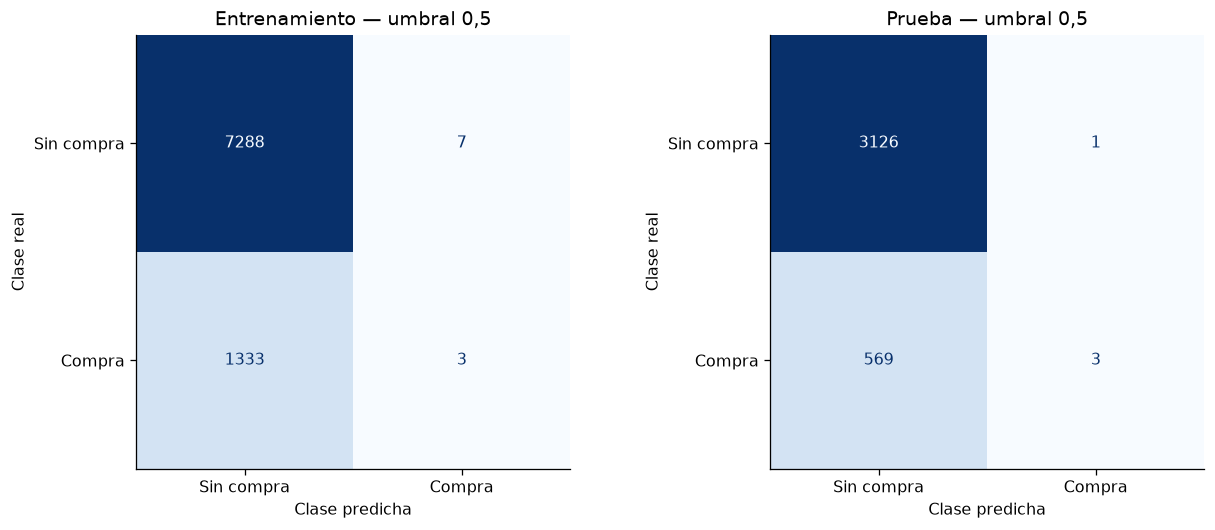

**Figura 1. Matrices de confusión: filas reales y columnas predichas. Se conserva el umbral de referencia.** Fuente: elaboración del grupo, datos UCI.

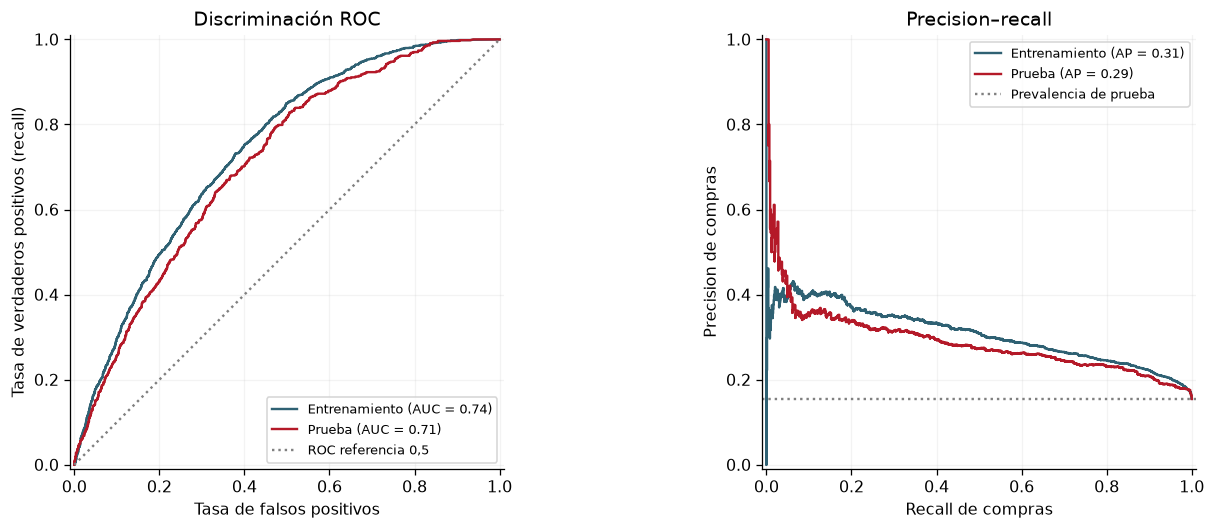

**Figura 2. Curvas ROC y precision–recall. AP y ROC-AUC resumen puntuaciones, no el umbral 0,5.** Fuente: elaboración del grupo, datos UCI.

**Interpretación del modelo inicial.** En prueba, el modelo obtiene ROC-AUC 0,711, accuracy 84,59 %, precision 75,00 %, recall 0,52 % y F1 0,010. Identifica 3 de 572 compras, omite 569 y genera 1 falsas alarmas. El resultado corresponde a la especificación, imputación y umbral fijados; no demuestra causalidad ni utilidad comercial automática.

**Limitación importante:** identifica menos de la mitad de las compras al umbral 0,5. La ponderación y el punto de operación se evaluarán en S3 usando entrenamiento; no se modifica el umbral ahora para mejorar retrospectivamente este conjunto de prueba.

**Cautela con precision:** se calcula sobre 4 predicciones positivas de prueba. Una precision alta basada en tan pocas alertas no demuestra estabilidad ni compensa las compras omitidas. El modelo inicial no resulta adecuado para detectar la mayoría de las compras con esta configuración.

In [22]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),constrained_layout=True)
for ax,nombre in zip(axes,['Entrenamiento','Prueba']):
    ConfusionMatrixDisplay(MATRICES[nombre],display_labels=['Sin compra','Compra']).plot(
        ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.grid(False);ax.set_title(nombre+' — umbral 0,5')
    ax.set_xlabel('Clase predicha');ax.set_ylabel('Clase real')
figura('Matrices de confusión: filas reales y columnas predichas. Se conserva el umbral de referencia.')
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for nombre,yy,pp,color in [('Entrenamiento',y_train,prob_train,COLOR[0]),('Prueba',y_test,prob_test,COLOR[1])]:
    RocCurveDisplay.from_predictions(yy,pp,name=nombre,ax=axes[0],curve_kwargs={'color':color})
    PrecisionRecallDisplay.from_predictions(yy,pp,name=nombre,ax=axes[1],curve_kwargs={'color':color})
axes[0].plot([0,1],[0,1],ls=':',color='grey',label='ROC referencia 0,5')
axes[0].set_title('Discriminación ROC');axes[0].legend(fontsize=8)
axes[0].set_xlabel('Tasa de falsos positivos');axes[0].set_ylabel('Tasa de verdaderos positivos (recall)')
axes[1].axhline(y_test.mean(),color='grey',ls=':',label='Prevalencia de prueba')
axes[1].set_title('Precision–recall');axes[1].legend(fontsize=8)
axes[1].set_xlabel('Recall de compras');axes[1].set_ylabel('Precision de compras')
figura('Curvas ROC y precision–recall. AP y ROC-AUC resumen puntuaciones, no el umbral 0,5.')
r_test=tabla_metricas.set_index('conjunto').loc['Prueba']
lectura_desempeno=(f'En prueba, el modelo obtiene ROC-AUC {numero(r_test.ROC_AUC)}, '
    f'accuracy {numero(100*r_test.accuracy,2)} %, precision {numero(100*r_test.precision,2)} %, '
    f'recall {numero(100*r_test.recall,2)} % y F1 {numero(r_test.F1)}. '
    f'Identifica {int(r_test.TP)} de {int(r_test.compras)} compras, omite {int(r_test.FN)} '
    f'y genera {int(r_test.FP)} falsas alarmas. '
    'El resultado corresponde a la especificación, imputación y umbral fijados; no demuestra causalidad ni utilidad comercial automática.')
display(Markdown('**Interpretación del modelo inicial.** '+lectura_desempeno))
if r_test.recall<.5:
    display(Markdown('**Limitación importante:** identifica menos de la mitad de las compras al umbral 0,5. '
        'La ponderación y el punto de operación se evaluarán en S3 usando entrenamiento; '
        'no se modifica el umbral ahora para mejorar retrospectivamente este conjunto de prueba.'))
display(Markdown('**Cautela con precision:** se calcula sobre '+str(int(r_test.TP+r_test.FP))+
    ' predicciones positivas de prueba. Una precision alta basada en tan pocas alertas no demuestra '+
    'estabilidad ni compensa las compras omitidas. El modelo inicial no resulta adecuado para detectar '+
    'la mayoría de las compras con esta configuración.'))

## 6. Auditoría de imputación, calidad de partición y límites

Una vez fijado y evaluado el modelo, se contrasta la imputación por mediana con los valores
verdaderos de las posiciones ocultadas. **Es una evaluación**, no información utilizada para
reconstruirlos. El entrenamiento y prueba usan la misma mediana aprendida únicamente con
entrenamiento. Los errores se expresan en minutos para facilitar interpretación.

La mediana minimiza error absoluto para una imputación constante, pero no recupera la variación
individual ni las asociaciones con otras variables. Las predicciones de los faltantes serán
idénticas; la imputación por regresión y la comparación de estrategias se desarrollarán en S3.

**Filas idénticas:** S1 identificó 125 duplicados exactos. Se conserva la partición por sesión
solicitada y se informa si hay perfiles de predictores repetidos entre conjuntos. Una repetición
no demuestra mismo usuario; el CSV carece de identificadores para validar dependencia.
No se afirma independencia garantizada ni se eliminan filas después de mirar prueba.

**Tabla 13. Error de imputación simple en valores ocultados; ninguna verdad se usa para ajustar**

,conjunto,n_ocultos,mediana_aplicada_min,MAE_min,RMSE_min,sesgo_imputado_menos_real_min
0,Entrenamiento,854,"9,9168","15,9631","30,4959","-9,6816"
1,Prueba,379,"9,9168","17,9108","34,8734","-11,5920"


**Tabla 14. Registro exacto de imputación para reutilizar en S3**

,variable,mediana_train_seg,imputados_train,imputados_test,estrategia
0,ProductRelated_Duration,"595,0095",854,379,"Mediana de entrenamiento, antes de log1p(minutos)"


**Dependencia no verificable:** 311 sesiones de prueba comparten exactamente el perfil de estos tres predictores con alguna sesión de entrenamiento. No sabemos si corresponden a la misma entidad. La evaluación es interna por sesiones, no validación por usuario o temporal.

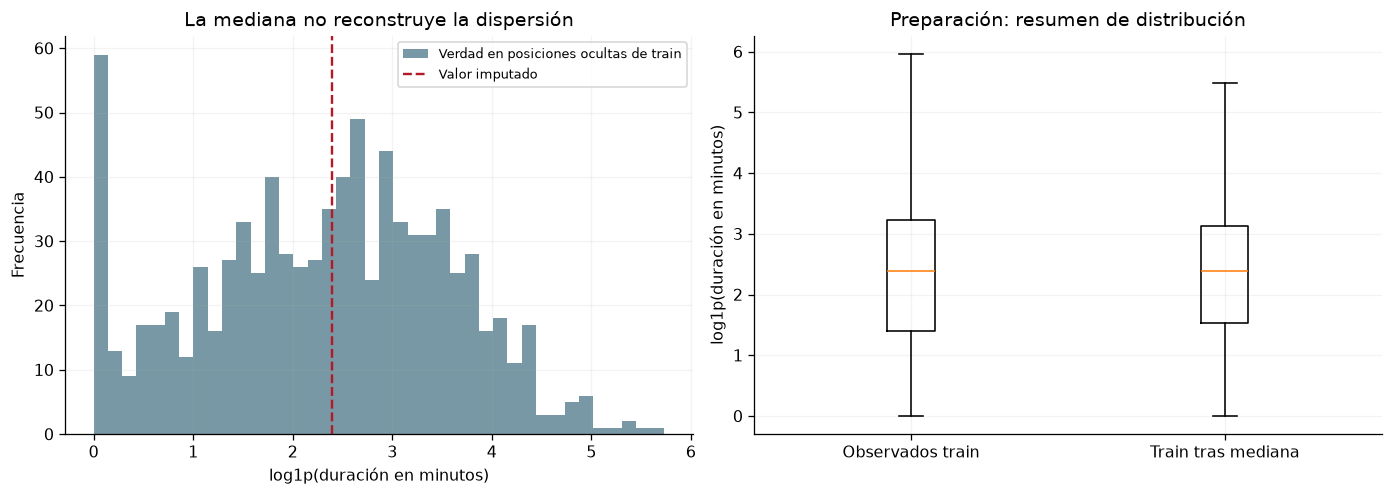

**Figura 3. Auditoría de mediana usando entrenamiento. No mostrar fliers en el boxplot no implica eliminarlos.** Fuente: elaboración del grupo, datos UCI.

In [23]:
mediana_train=float(modelo.named_steps['preparacion'].named_transformers_[VARIABLE_MCAR]
                    .named_steps['imputacion'].statistics_[0])
assert mediana_train==float(X_train[VARIABLE_MCAR].median())
filas_error=[]
for nombre,idx in [('Entrenamiento',train_idx),('Prueba',test_idx)]:
    ids=idx[X.loc[idx,VARIABLE_MCAR].isna().to_numpy()]
    verdaderos=original.loc[ids,VARIABLE_MCAR].to_numpy()/60.
    imputados=np.repeat(mediana_train/60.,len(ids))
    filas_error.append({'conjunto':nombre,'n_ocultos':len(ids),'mediana_aplicada_min':mediana_train/60.,
        'MAE_min':mean_absolute_error(verdaderos,imputados),
        'RMSE_min':np.sqrt(mean_squared_error(verdaderos,imputados)),
        'sesgo_imputado_menos_real_min':float(np.mean(imputados-verdaderos))})
tabla_error=pd.DataFrame(filas_error)
tabla(tabla_error,'Error de imputación simple en valores ocultados; ninguna verdad se usa para ajustar')
assert tabla_error.n_ocultos.sum()==1233
tabla_imputacion=pd.DataFrame([{'variable':VARIABLE_MCAR,'mediana_train_seg':mediana_train,
    'imputados_train':int(X_train[VARIABLE_MCAR].isna().sum()),
    'imputados_test':int(X_test[VARIABLE_MCAR].isna().sum()),
    'estrategia':'Mediana de entrenamiento, antes de log1p(minutos)'}])
tabla(tabla_imputacion,'Registro exacto de imputación para reutilizar en S3')
# Auditoría de coincidencias de perfiles, sin alterar la partición ni el ajuste.
hash_perfiles=pd.util.hash_pandas_object(original[PREDICTORES],index=False)
perfiles_train=set(hash_perfiles.loc[train_idx].tolist())
coincidentes_test=int(hash_perfiles.loc[test_idx].isin(perfiles_train).sum())
duplicados_auditoria={'filas_identicas_adicionales_S1':int(S1['filas_identicas_adicionales']),
    'sesiones_prueba_con_perfil_predictor_igual_a_alguna_train':coincidentes_test,
    'alcance':'Coincidencias de valores agregados; no identifican usuarios ni prueban duplicación de entidad.'}
display(Markdown('**Dependencia no verificable:** '+str(coincidentes_test)+
    ' sesiones de prueba comparten exactamente el perfil de estos tres predictores con alguna sesión de entrenamiento. '
    'No sabemos si corresponden a la misma entidad. La evaluación es interna por sesiones, no validación por usuario o temporal.'))
fig,axes=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
ocultas_train=train_idx[X.loc[train_idx,VARIABLE_MCAR].isna().to_numpy()]
axes[0].hist(np.log1p(original.loc[ocultas_train,VARIABLE_MCAR]/60.),bins=40,
             color=COLOR[0],alpha=.65,label='Verdad en posiciones ocultas de train')
axes[0].axvline(np.log1p(mediana_train/60.),color=COLOR[1],ls='--',label='Valor imputado')
axes[0].set(xlabel='log1p(duración en minutos)',ylabel='Frecuencia',title='La mediana no reconstruye la dispersión')
axes[0].legend(fontsize=8)
antes=X_train[VARIABLE_MCAR].dropna().to_numpy()/60.
despues=X_train[VARIABLE_MCAR].fillna(mediana_train).to_numpy()/60.
axes[1].boxplot([np.log1p(antes),np.log1p(despues)],tick_labels=['Observados train','Train tras mediana'],showfliers=False)
axes[1].set(ylabel='log1p(duración en minutos)',title='Preparación: resumen de distribución')
figura('Auditoría de mediana usando entrenamiento. No mostrar fliers en el boxplot no implica eliminarlos.')

## 7. Síntesis, revisión de la Formativa 2 y continuidad hacia S3

La evaluación formativa debe permitir explicar el primer flujo, detectar limitaciones y
obtener retroalimentación. No se presentan como realizadas las tareas pendientes de S3.
La revisión siguiente se basa en el correo docente y su ejemplo; **no se dispone aquí de una
rúbrica independiente de Formativa 2 para asignar una nota numérica**.

**Límites:** datos observacionales, variables agregadas al cierre de sesión, exploración previa
en el dataset completo, dependencia no verificable, imputación simple sin incertidumbre,
umbral fijo y ausencia de validación externa. Los resultados no justifican despliegue operativo.
No se interpreta el signo de un coeficiente como causal ni se asegura su estabilidad sin bootstrap.

**Categoría pequeña:** Other tenía solo 85 sesiones en S1. Su odds ratio puntual no debe presentarse como evidencia concluyente; su estabilidad e incertidumbre se evaluarán en S3.

In [25]:
revision_formativa=pd.DataFrame([
 {'requisito':'Usar S1/S2 sin repetir EDA','evidencia':'Sección 1: hashes, cifras y correlaciones previas','estado':'Implementado'},
 {'requisito':'MCAR 10–15 %, semilla y originales','evidencia':'Sección 2: 10 % (1.233), máscara y valores persistidos','estado':'Implementado'},
 {'requisito':'70/30 estratificado e imputación simple','evidencia':'Secciones 2–3: 8.631 / 3.699; mediana de entrenamiento','estado':'Implementado'},
 {'requisito':'Un logístico con 3–5 variables justificadas','evidencia':'Tres variables originales; candidatos S1/S2 y VIF explícitos','estado':'Implementado'},
 {'requisito':'Odds ratios y VIF','evidencia':'Secciones 3–4: referencia y unidad de cambio indicadas','estado':'Implementado'},
 {'requisito':'Matriz, métricas, ROC/AUC','evidencia':'Sección 5: train/test y referencia mayoritaria','estado':'Implementado'},
 {'requisito':'Síntesis y mejoras para S3','evidencia':'Secciones 6–7 y resultados exportados','estado':'Implementado'},
 {'requisito':'Reproducción por otro integrante y revisión conceptual','evidencia':'Pendiente de revisión del equipo','estado':'Pendiente humano'}])
tabla(revision_formativa,'Autoevaluación contra las orientaciones docentes de Formativa 2')
pendientes_s3=pd.DataFrame([
 {'tarea':'Imputación por regresión','detalle':'3–5 predictores justificados; casos completos de train; diagnósticos y error frente a verdades ocultas.'},
 {'tarea':'Tres estrategias de faltantes','detalle':'Eliminación, mediana y regresión; muestra, distribución, correlaciones y desempeño en poblaciones comparables.'},
 {'tarea':'Tres logísticas','detalle':'Informada por S1/S2, stepwise AIC y reducida; selección/validación solo dentro de train.'},
 {'tarea':'Ponderación de clase','detalle':'Comparar con la base sin pesos; pesos derivados de train. Evaluar recall, precision y discriminación.'},
 {'tarea':'Bootstrap e intervalos','detalle':'Reajustar modelo elegido; IC95 % coeficientes y OR; comparar tradicionales y conservación de signo.'},
 {'tarea':'Diagnósticos ampliados','detalle':'VIF, logit, residuos, influencia y estabilidad. No eliminar filas según resultados de prueba.'},
 {'tarea':'Coherencia de entrega','detalle':'Notebook/informe/video deben usar la misma versión y resultados; aclarar discrepancia de sección 1.1 de S2.'},
 {'tarea':'Momento de predicción','detalle':'Verificar disponibilidad temporal de variables; PageValues continúa excluida.'}])
tabla(pendientes_s3,'Ampliaciones necesarias: no forman parte de lo ya completado en Formativa 2')
salida={
 'schema_version':1,'fase':'Formativa 2','notebook':'Formativa2/Modelamiento_Predictivo.ipynb',
 'procedencia':{'CSV':str(CSV.relative_to(RAIZ)),'sha256_csv_LF':HASH_CSV,
    'S1':'S1/resultados_s1.json','sha256_S1_LF':sha_lf(S1_PATH),
    'S2':'S2/resultados_validados.json','sha256_S2_LF':sha_lf(S2_PATH),
    'preparacion':'data/preparacion_modelamiento.json','sha256_preparacion_LF':sha_lf(PROTOCOLO_PATH)},
 'configuracion':{'semilla_MCAR':SEED_MCAR,'semilla_split':SEED_SPLIT,'semilla_CV':SEED_CV,
    'fraccion_MCAR':FRACCION_MCAR,'variable_MCAR':VARIABLE_MCAR,'umbral':UMBRAL,'folds':CV_FOLDS,
    'predictoras_originales':PREDICTORES,'clase_positiva':'compra (Revenue=1)',
    'class_weight':None,'penalizacion':'ninguna (C=np.inf)','python':sys.version.split()[0],'versiones':VERSIONES,
    'referencia_categorica':'Returning_Visitor','diseno':'numéricas estandarizadas; log1p(minutos) en duración'},
 'diagnostico_kernel':diagnostico_kernel,
 'particion':registros(tabla_particion),'imputacion':registros(tabla_imputacion),
 'error_imputacion':registros(tabla_error),'vif_candidatas':registros(vif_candidatas),'vif_final':registros(vif_final),
 'coeficientes_OR':registros(tabla_coef),'intercepto':intercepto,'iteraciones_ajuste':n_iter,
 'validacion_interna_folds':registros(tabla_cv),'validacion_interna_resumen':registros(resumen_cv),
 'medianas_seg_por_fold':medianas_cv,'metricas':registros(tabla_metricas),'baseline':registros(baseline),
 'matrices_confusion':{c:m.tolist() for c,m in MATRICES.items()},
 'pesos_propuestos_S3_no_aplicados':registros(pesos_s3),'auditoria_coincidencias':duplicados_auditoria,
 'interpretacion_desempeno':lectura_desempeno,'revision_formativa':registros(revision_formativa),
 'pendientes_S3':registros(pendientes_s3),
 'limites':['No predicción en tiempo real demostrada; datos agregados de sesión.',
   'S1/S2 exploraron datos completos; prueba interna no equivale a validación externa.',
   'Independencia por usuario no verificable; coincidencias de perfiles auditadas.',
   'Mediana reduce dispersión y no incorpora incertidumbre de imputación.',
   'Umbral 0.5 y sin pesos: no optimizados con prueba; coeficientes aún sin intervalos.',
   'PageValues excluida; sin interpretación causal de coeficientes ni asociaciones.']}
RESULTADOS_PATH=RAIZ/'Formativa2/resultados_formativa2.json'
RESULTADOS_PATH.write_text(json.dumps(salida,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
assert sha_lf(CSV)==HASH_CSV, 'No debe alterarse el CSV original.'
assert all(not {'PageValues','Revenue'} & set(PREDICTORES) for _ in [0])
assert len(revision_formativa.loc[revision_formativa.estado=='Implementado'])==7
assert datos.isna().sum().sum()==1233
print('Resultados:',RESULTADOS_PATH.relative_to(RAIZ))
print('Preparación compartida para S3:',PROTOCOLO_PATH.relative_to(RAIZ))
print('Tablas:',TABLAS,'| Figuras:',FIGURAS,'| Segundos:',round(perf_counter()-INICIO,2))
print('No se realiza commit, push ni entrega en Canvas. Revisión del grupo pendiente.')

**Tabla 17. Autoevaluación contra las orientaciones docentes de Formativa 2**

,requisito,evidencia,estado
0,Usar S1/S2 sin repetir EDA,"Sección 1: hashes, cifras y correlaciones previas",Implementado
1,"MCAR 10–15 %, semilla y originales","Sección 2: 10 % (1.233), máscara y valores persistidos",Implementado
2,70/30 estratificado e imputación simple,Secciones 2–3: 8.631 / 3.699; mediana de entrenamiento,Implementado
3,Un logístico con 3–5 variables justificadas,Tres variables originales; candidatos S1/S2 y VIF explícitos,Implementado
4,Odds ratios y VIF,Secciones 3–4: referencia y unidad de cambio indicadas,Implementado
5,"Matriz, métricas, ROC/AUC",Sección 5: train/test y referencia mayoritaria,Implementado
6,Síntesis y mejoras para S3,Secciones 6–7 y resultados exportados,Implementado
7,Reproducción por otro integrante y revisión conceptual,Pendiente de revisión del equipo,Pendiente humano


**Tabla 18. Ampliaciones necesarias: no forman parte de lo ya completado en Formativa 2**

,tarea,detalle
0,Imputación por regresión,3–5 predictores justificados; casos completos de train; diagnósticos y error frente a verdades ocultas.
1,Tres estrategias de faltantes,"Eliminación, mediana y regresión; muestra, distribución, correlaciones y desempeño en poblaciones comparables."
2,Tres logísticas,"Informada por S1/S2, stepwise AIC y reducida; selección/validación solo dentro de train."
3,Ponderación de clase,"Comparar con la base sin pesos; pesos derivados de train. Evaluar recall, precision y discriminación."
4,Bootstrap e intervalos,Reajustar modelo elegido; IC95 % coeficientes y OR; comparar tradicionales y conservación de signo.
5,Diagnósticos ampliados,"VIF, logit, residuos, influencia y estabilidad. No eliminar filas según resultados de prueba."
6,Coherencia de entrega,Notebook/informe/video deben usar la misma versión y resultados; aclarar discrepancia de sección 1.1 de S2.
7,Momento de predicción,Verificar disponibilidad temporal de variables; PageValues continúa excluida.


Resultados: Formativa2\resultados_formativa2.json
Preparación compartida para S3: data\preparacion_modelamiento.json
Tablas: 18 | Figuras: 3 | Segundos: 322.73
No se realiza commit, push ni entrega en Canvas. Revisión del grupo pendiente.


### Referencias y cómo continuar

1. Sakar, C. y Kastro, Y. (2018). Online Shoppers Purchasing Intention. UCI. https://doi.org/10.24432/C5F88Q
2. Resultados propios de Grupo 2: `S1/resultados_s1.json` y `S2/resultados_validados.json`.
3. Ruete, D. y Maidana, J. P. (2026). Correo «Apoyo para la Formativa 2 y Sumativa 3», aportado por el equipo.
4. Maidana, J. P. (2026). Retroalimentación de Sumativa 2, Canvas, 20 de octubre.
5. Ejemplo docente Formativa 2: https://github.com/jpmaidana/MCDI501-202682/tree/main/03-evaluaciones/formativa-2-modelamiento-predictivo
6. Apuntes de Semana 3: https://github.com/jpmaidana/MCDI501-202682/tree/main/01-apuntes/Semana03
7. Scikit-learn. LogisticRegression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
8. Scikit-learn. Prevención de filtración y pipelines: https://scikit-learn.org/stable/common_pitfalls.html

**Para revisar juntos:** empezar por la sección 2 (MCAR), después 3 (VIF y preparación),
4 (odds ratios) y 5 (recall frente a AUC). Guardar el notebook ejecutado. Para S3 se reutiliza
la preparación compartida, sin regenerar faltantes ni partición y sin convertir verdad oculta en predictor.